# Data Understanding

Data understanding is the phase where you explore, describe, and verify your data before modeling. It’s about knowing what you’re working with, the data types, distributions, relationships, missing values, and potential issues. Good data understanding ensures your later analysis is meaningful and reliable.

You should already know the basics of data understanding (see the prerequisites on the course homepage), such as checking missing values, `describe` and `info` methods etc. If you need a refresher, the [pandas getting started tutorials](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html) cover them. In this notebook we will cover intermediate concepts. Some of them use the tools from [Data Preparation](01_data_prep.ipynb), such as scaling before PCA: that is why that notebook comes first in this course, although Data Preparation follows Data Understanding in CRISP-DM.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Understanding the Distribution of Each Variable

A distribution shows how values in your dataset are spread or concentrated. It reveals patterns such as skewness, outliers, and common ranges, helping you understand the typical and extreme cases. Knowing the distribution of each variable is essential because it influences which models, transformations, and evaluation methods are appropriate.

In [2]:
from sklearn.datasets import fetch_california_housing
X, y = fetch_california_housing(as_frame=True, return_X_y=True)

We use histograms to infer the distribution of the data. Histograms are graphical representations that group data into bins and show the frequency of values within each bin. `pandas` makes it very easy to plot histograms.

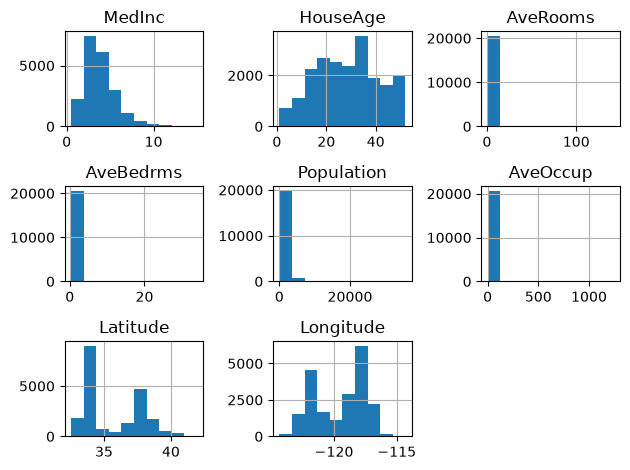

In [3]:
X.hist()
plt.tight_layout()

you could also use matplotlib:

(array([ 719., 1104., 2235., 2681., 2510., 2354., 3555., 1900., 1616.,
        1966.]),
 array([ 1. ,  6.1, 11.2, 16.3, 21.4, 26.5, 31.6, 36.7, 41.8, 46.9, 52. ]),
 <BarContainer object of 10 artists>)

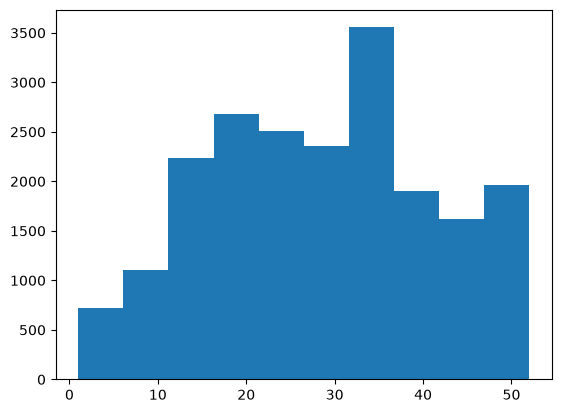

In [4]:
plt.hist(X['HouseAge'])

the default number of bins in matplotlib is 10. You can adjust it and as you can see it might suddenly give a different view:

(array([  62.,   62.,  191.,  244.,  160.,  175.,  206.,  205.,  264.,
         254.,  238.,  302.,  412.,  512.,  771.,  698.,  570.,  502.,
         465.,  446.,  399.,  448.,  478.,  566.,  619.,  488.,  471.,
         461.,  476.,  458.,  565.,  615.,  689.,  824.,  862.,  537.,
         394.,  369.,  304.,  296.,  368.,  353.,  356.,  294.,  245.,
         198.,  177.,  134.,  136., 1321.]),
 array([ 1.  ,  2.02,  3.04,  4.06,  5.08,  6.1 ,  7.12,  8.14,  9.16,
        10.18, 11.2 , 12.22, 13.24, 14.26, 15.28, 16.3 , 17.32, 18.34,
        19.36, 20.38, 21.4 , 22.42, 23.44, 24.46, 25.48, 26.5 , 27.52,
        28.54, 29.56, 30.58, 31.6 , 32.62, 33.64, 34.66, 35.68, 36.7 ,
        37.72, 38.74, 39.76, 40.78, 41.8 , 42.82, 43.84, 44.86, 45.88,
        46.9 , 47.92, 48.94, 49.96, 50.98, 52.  ]),
 <BarContainer object of 50 artists>)

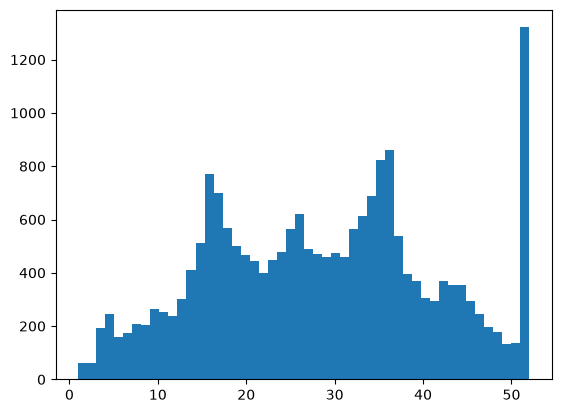

In [5]:
plt.hist(X['HouseAge'], bins=50)

Two very important points:

- The number of bins you choose can dramatically change how the dataset appears.
- We don’t plot distributions just for fun. As a competent data scientist, you should be alerted by unusual patterns such as the sudden spike after 50 and investigate their cause. Here the spike is at 52 years: the dataset records every district with older houses as 52 (1,273 districts). The target is capped the same way, at 5.0 ($500,000, 992 districts). A capped value is not the real one, and a model trained on it cannot learn prices above the cap.

## 2. Exploring Relationships Between Variables

The distribution of a variable tells us about that variable alone. However, in machine learning, we work with multiple features and a target, and understanding the relationships between them is key. If two features are highly related, for instance, one column shows length in centimeters and another shows length in inches, they contain the same information. Keeping both adds no information. Whether to drop one depends on the model: for predictions, correlated features rarely hurt (tree-based models handle them well), but they make the coefficients of a linear model unstable and split the feature importances between them. Decide with validation, not by rule. On the other hand, if a feature shows a strong relationship with the target variable, that’s a sign it may be useful for prediction. By exploring these relationships, we can identify which features provide real value and which ones add noise or duplication.

The most intuitive way to explore the relationship between two variables is to plot them together, placing one variable on the x-axis and the other on the y-axis.

Text(0, 0.5, 'Median House Value')

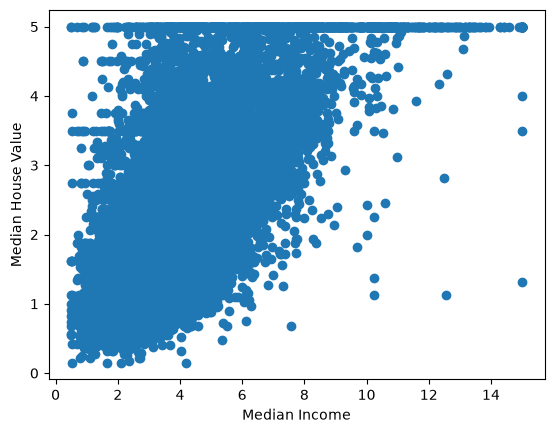

In [6]:
plt.scatter(X['MedInc'], y)
plt.xlabel('Median Income')
plt.ylabel('Median House Value')

Looking at this plot, we can see that blocks with higher median income tend to have higher median house values. Alternatively, we can say that as the median house value of a block increases, there is a tendency for the income to rise as well. This relationship makes sense because families with higher incomes can typically afford more expensive homes, leading to this positive association.

However, we cannot say that one causes the other, because correlation does not imply causation. Both variables may be influenced by other underlying factors such as location, proximity to job opportunities, or neighborhood quality, which can independently affect both income and house value.

Please read the following Wiki: https://en.wikipedia.org/wiki/Correlation_does_not_imply_causation

The relationship above shows how a feature relates to the target variable, and in general, we prefer features that have a clear connection with the target. However, the absence of an obvious relationship does not necessarily mean that a feature is useless, it might still contribute valuable information when combined with others.

Now, let’s look at a relationship between two features:

Text(0, 0.5, 'AveBedrms')

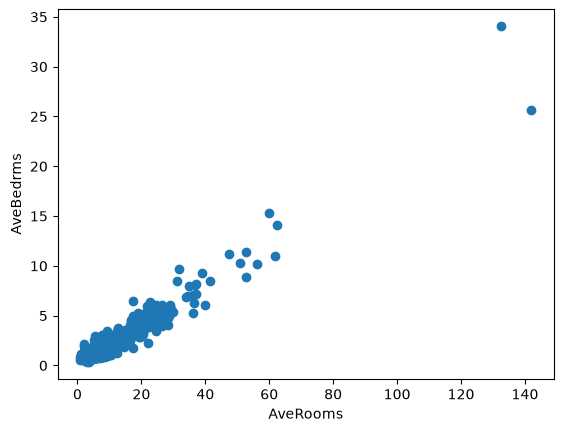

In [7]:
plt.scatter(X['AveRooms'], X['AveBedrms'])
plt.xlabel('AveRooms')
plt.ylabel('AveBedrms')

This relationship also makes sense: if a house has more rooms, we would naturally expect it to have more bedrooms, and vice versa. The two features contain overlapping information. That rarely hurts the predictions, but it makes the coefficients of a linear model unstable and splits the importance between the two features in a tree-based model. Whether to keep both is a question for validation (Theme 3).

We can also quantify the strength of relationships between variables, with the most common measure being correlation. However, the usual (Pearson) correlation captures only linear relationships; the Spearman correlation, `df.corr(method='spearman')`, captures any relationship that only goes up or only goes down, while non-linear relationships can still hold valuable information for machine learning models. In `pandas` it is very easy to check the correlation between all the columns as follows: 

In [8]:
X.corr()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000


because X does not contain y, we only see the feature-feature correlations. We can create a new df that combines X and y to see all correlations:

In [9]:
df = X.copy()
df['target'] = y

df.corr()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
target,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


We can see that the correlation between `AveBedrms` and `AveRooms` is 0.85, and between `MedInc` and the `target` is 0.69, both quite high, as expected. This numerical approach allows us to quickly identify and filter strong correlations without having to plot each pair. For example, we can find the feature most strongly correlated with the target as follows:

In [10]:
df.corr()['target'].sort_values(ascending=False)

target        1.000000
MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: target, dtype: float64

## 3. Principal Component Analysis (PCA)

We have explored relationships between pairs of variables and examined their distributions. But is there a way to look at all the data at once? Each data point here is described by eight features, and since we cannot visualize an eight-dimensional plot, we are limited to viewing only two dimensions at a time (3D at best). PCA helps overcome this limitation by projecting high-dimensional data into two or three dimensions that capture most of the variation, allowing us to see the overall structure and patterns in the dataset. It reduces the dimensions from eight to two hence the name [dimensionality reduction](https://en.wikipedia.org/wiki/Dimensionality_reduction).

We can perform PCA easily using scikit-learn. For now, ignore the code and focus on understanding the output.

Text(0.5, 1.0, 'PCA projection to 2 components')

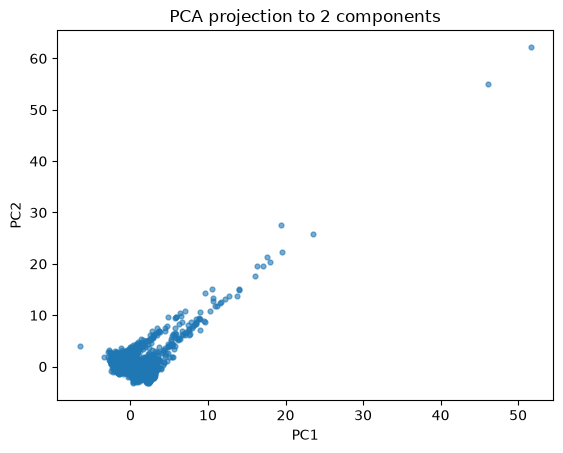

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1) Scale features (important for PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2) Fit PCA to 2 components
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X_scaled)

# 3) Put into a DataFrame (optional)
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'], index=X.index)

# 4) Plot the two components
plt.figure()
plt.scatter(pca_df['PC1'], pca_df['PC2'], s=12, alpha=0.6)
plt.xlabel(f"PC1")
plt.ylabel(f"PC2")
plt.title("PCA projection to 2 components")

This plot shows the result of projecting the California housing data onto two principal components using PCA. Each point represents one district from the dataset, summarized by eight original features and reduced to two dimensions (PC1 and PC2).

We can see that most data points cluster near the origin, meaning most districts have similar overall feature patterns. A few points lie far from the cluster, indicating districts that differ strongly from the average, these could be outliers. A look at their original features shows what they are: districts with very few residents and an implausibly large number of rooms per household (50 to 140, against a median of about 5), probably holiday homes.

In machine learning, an important use of PCA is to examine the distribution of the data source. By projecting both the training and test sets onto the principal components, we can visually check whether they come from similar distributions. For example, if your training data contains black and orange cats while your test data contains only white cats, PCA would reveal that the test samples form a separate cluster. This indicates a distribution shift, meaning the model may not generalize well because the test data differ significantly from what it has seen during training.

Now let's look at the code:

In [12]:
# why did we scale X?
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

PCA is sensitive to the scale of features because it relies on variance. If one feature (like income) has much larger values than another (like number of bedrooms), it would dominate the principal components. `StandardScaler` fixes this by transforming every feature to have mean = 0 and standard deviation = 1, so that every feature has the same variance before PCA and none dominates because of its unit.

We fit the scaler and PCA on all of `X` here. For exploring data that is fine. When PCA becomes a step of a model, it is fitted on the training data only, like every other step that learns from data (see Data Preparation).

In [13]:
# fit_transform was discussed in the previous notebook
# n_components is the important parameter here
# random state for repeatable results
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X_scaled)

Here we apply PCA to the scaled data and ask for two principal components (`n_components=2`). PCA finds the two directions (linear combinations of the original features) that capture the most variance in the data. `X_pca` is the new dataset with only two columns, these are the coordinates of each data point in the new 2D space that summarizes most of the original information.

PCA works by finding new axes (principal components) that are linear combinations of the original features. As a result, PCA cannot represent nonlinear patterns in the data.

Therefore there are other dimensionality reduction techniques worth exploring. Two popular nonlinear methods are:

* **t-SNE** (available in scikit-learn): [t-SNE documentation](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)
* **UMAP** (available through its own library): [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/)

These techniques can capture complex, nonlinear relationships in the data that PCA might miss. They are valuable tools to visualize high-dimensional data and to explore clusters or patterns beyond what PCA can reveal.


## 4. Exercise

<mark>YOUR TURN</mark>

Plot the breast cancer dataset using PCA reduced to 2 dimensions, and color the data points according to their class labels (y). Add axis labels, a title, and a legend. Then reflect on what you see, do the two classes separate clearly in this 2D projection?

Important: do not use `y` when performing PCA, apply PCA only to `X` like we have done above, and scale `X` first. After the transformation, color the points by their class labels (`y`) when plotting.

In [14]:
from sklearn.datasets import load_breast_cancer
X, y = load_breast_cancer(as_frame=True, return_X_y=True)

In [15]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


<details>
<summary>What you should see</summary>

Two groups that overlap only partly, mainly along the first principal component (PC1): the malignant tumors spread out to one side, the benign ones are more compact. PCA did not use the labels, yet two components already separate the classes well: a logistic regression on just PC1 and PC2 reaches about 0.95 accuracy in 5-fold cross-validation.

</details>